# 06 - Grade Distribution By Course
**Research question:** How do final grade distributions vary across currently offered NetMath courses during summer semesters?

- Scope: **Summer 2020, 2021, 2022** (AY 2019-20, 2020-21, 2021-22).
- **Why not Summer 2024–2026:** those final grades are not stored in nexus. Share of Completed summer enrollments with a `finalGrade`: ~100% through Summer 2022, 330/573 in Summer 2023, 1/469 in 2024, 0 in 2025 and 2026. Every nexus collection was checked on 2026-11-12 (`finalgrades`, `grades`, `netmathgrades`, `moodlegrades`, `mathablegrades`, `tmp_students`, `comments`, …) and none holds them. Summer 2020–2022 are the three most recent summers with complete grades; this is a fallback until the Summer 2024–2026 grades are obtained from outside nexus.
- Unit: one row = one enrollment (`students` document).
- Main metric: share of each original letter grade (A+ … F) among enrollments with a letter grade. `W` / `Abs` / no grade are reported separately.

In [53]:
import sys

sys.path.append("..")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.mongo_connect import get_db

db = get_db()
print(db.name)

OUTPUT_DIR = Path("../src/output_graphs_06")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

nexus


## 1. Data Preparation

### 1.1 Filter academic years
Same academic-year rule as notebook 05: a term ending in `8` (Fall) starts the academic year, so Spring and Summer belong to the year before.

| Academic Year | Summer semester | term code |
|---|---|---|
| 2019-20 | Summer 2020 | `120205` |
| 2020-21 | Summer 2021 | `120215` |
| 2021-22 | Summer 2022 | `120225` |

In [54]:
ACADEMIC_YEARS = ["2019-20", "2020-21", "2021-22"]
SUMMER_TERMS = {120205: "Summer 2020", 120215: "Summer 2021", 120225: "Summer 2022"}
YEARS_LABEL = "Summer 2020–2022"

def term_to_academic_year(term):
    code = str(term)
    year = int(code[1:5])
    start = year if code.endswith("8") else year - 1
    return f"{start}-{str(start + 1)[2:]}"

assert [term_to_academic_year(t) for t in SUMMER_TERMS] == ACADEMIC_YEARS

### 1.2 Filter Summer semesters
`term` = `1YYYYT`, `T = 5` is Summer. First check that the codes really exist in `students`: list every term in the AY 2019-20 to 2021-22 window with its row count.

In [55]:
term_counts = pd.Series({
    t: db.students.count_documents({"term": t})
    for t in db.students.distinct("term", {"term": {"$gte": 120198, "$lte": 120227}})
}).sort_index()
term_counts.index = term_counts.index.astype(int)
display(term_counts.rename("rows").to_frame().assign(
    academic_year=[term_to_academic_year(t) for t in term_counts.index],
    last_digit=[str(t)[-1] for t in term_counts.index],
))

,rows,academic_year,last_digit
120198,3,2019-20,8
120201,3,2019-20,1
120205,1074,2019-20,5
120207,1582,2019-20,7
120208,4,2020-21,8
120215,706,2020-21,5
120217,1435,2020-21,7
120218,1,2021-22,8
120221,2,2021-22,1
120225,1187,2021-22,5


In [56]:
df_summer = pd.DataFrame(list(db.students.find(
    {"term": {"$in": list(SUMMER_TERMS)}},
    {"netId": 1, "term": 1, "course": 1, "status": 1, "finalGrade": 1},
)))
df_summer["term"] = df_summer["term"].astype(int)
df_summer["course"] = df_summer["course"].astype(int)
df_summer["semester"] = df_summer["term"].map(SUMMER_TERMS)
df_summer["academic_year"] = df_summer["term"].map(term_to_academic_year)

print("summer rows:", len(df_summer))
pd.crosstab(df_summer["course"], df_summer["semester"], margins=True, margins_name="total")

summer rows: 2967


semester,Summer 2020,Summer 2021,Summer 2022,total
course,,,,
112,12,4,5,21
114,6,0,7,13
115,13,13,13,39
220,57,33,65,155
231,97,67,132,296
241,151,147,144,442
257,0,70,280,350
285,103,51,131,285
286,47,29,0,76


### 1.3 Only include currently offered courses
The current course list comes from the **official NetMath course catalog** (read 2026-11-12), not from enrollment data:
- AY Course Catalog (https://netmath.illinois.edu/academics/netmath-course-catalog): MATH 241, 257, 285, 314, 416, 417, 423, 441, 442, 444, 446, 447, 448, 453.
- Summer Semester Catalog (https://netmath.illinois.edu/summer-semester-courses-uiuc-only): MATH 241, 257, 285, 314, 416, 417, 441, 444.

A course counts as current if it is in the AY catalog (so a course with no students in these summers is not treated as discontinued). Anything else in the summer data is a course NetMath no longer offers and is dropped.

⚠️ Confirm this list with the supervisor before the final report.

In [57]:
CURRENT_COURSES = [241, 257, 285, 314, 416, 417, 423, 441, 442, 444, 446, 447, 448, 453]
SUMMER_CATALOG = [241, 257, 285, 314, 416, 417, 441, 444]

course_check = df_summer.groupby("course").size().rename("summer_rows").to_frame()
course_check["current"] = course_check.index.isin(CURRENT_COURSES)
course_check["in_summer_catalog"] = course_check.index.isin(SUMMER_CATALOG)
display(course_check)

print("dropped (no longer offered):", course_check.index[~course_check["current"]].tolist(),
      "|", course_check.loc[~course_check["current"], "summer_rows"].sum(), "rows")
print("current courses with no summer rows:", sorted(set(CURRENT_COURSES) - set(course_check.index)))

df_summer = df_summer[df_summer["course"].isin(CURRENT_COURSES)].copy()
print("rows kept:", len(df_summer))

,summer_rows,current,in_summer_catalog
course,,,
112,21,False,False
114,13,False,False
115,39,False,False
220,155,False,False
231,296,False,False
241,442,True,True
257,350,True,True
285,285,True,True
286,76,False,False


dropped (no longer offered): [112, 114, 115, 220, 231, 286, 292, 347, 415, 461, 481] | 1264 rows
current courses with no summer rows: [314, 423, 442, 448, 453]
rows kept: 1703


### 1.4 Match final grades
Grades live in `nexus.finalgrades`; `nexus.students` only links to them. Two links, in order of priority:
1. `students.finalGrade` → `finalgrades._id` (same as notebooks 02, 04, 05)
2. `finalgrades.student` → `students._id` (back-reference; if an enrollment has several, keep the most recent `created`)

`grade_source` records which link each grade came from.

In [58]:
df_summer = df_summer.drop(columns=["finalGradeLetter", "grade_source"], errors="ignore")
if "finalGrade" not in df_summer:
    df_summer["finalGrade"] = None

# route 1: students.finalGrade -> finalgrades._id
pointer = pd.DataFrame(list(db.finalgrades.find(
    {"_id": {"$in": df_summer["finalGrade"].dropna().tolist()}}, {"grade": 1}
)), columns=["_id", "grade"]).rename(columns={"_id": "finalGrade", "grade": "grade_by_pointer"})

# route 2: finalgrades.student -> students._id
backref = pd.DataFrame(list(db.finalgrades.find(
    {"student": {"$in": df_summer["_id"].tolist()}}, {"student": 1, "grade": 1, "created": 1}
)), columns=["student", "grade", "created"])
print("finalgrades docs pointing to these enrollments:", len(backref),
      "| enrollments with more than one:", (backref["student"].value_counts() > 1).sum())
backref = (backref.sort_values("created").drop_duplicates("student", keep="last")
           .rename(columns={"student": "_id", "grade": "grade_by_backref"})[["_id", "grade_by_backref"]])

rows_before = len(df_summer)
df_summer = df_summer.merge(pointer, on="finalGrade", how="left").merge(backref, on="_id", how="left")
assert len(df_summer) == rows_before

conflicts = df_summer["grade_by_pointer"].notna() & df_summer["grade_by_backref"].notna() & \
            (df_summer["grade_by_pointer"] != df_summer["grade_by_backref"])
print("routes disagree:", conflicts.sum())

df_summer["finalGradeLetter"] = df_summer["grade_by_pointer"].fillna(df_summer["grade_by_backref"])
df_summer["grade_source"] = np.select(
    [df_summer["grade_by_pointer"].notna(), df_summer["grade_by_backref"].notna()],
    ["students.finalGrade", "finalgrades.student"], default="not matched",
)
df_summer = df_summer.drop(columns=["grade_by_pointer", "grade_by_backref"])

# match rate, overall and for Completed enrollments
print()
display(pd.crosstab(df_summer["status"], df_summer["grade_source"], margins=True, margins_name="total"))
completed = df_summer[df_summer["status"] == "Completed"]
print(f"Completed enrollments with a final grade: {completed['finalGradeLetter'].notna().sum()} of {len(completed)}")
display(pd.crosstab(completed["course"], completed["finalGradeLetter"].notna().map({True: "matched", False: "not matched"}),
                    margins=True, margins_name="total"))

finalgrades docs pointing to these enrollments: 726 | enrollments with more than one: 2
routes disagree: 0



grade_source,not matched,students.finalGrade,total
status,,,
Completed,2,723,725
Withdrawn,977,1,978
total,979,724,1703


Completed enrollments with a final grade: 723 of 725


finalGradeLetter,matched,not matched,total
course,,,
241,110,0,110
257,200,1,201
285,135,0,135
416,82,0,82
417,70,1,71
441,72,0,72
444,41,0,41
446,12,0,12
447,1,0,1


### 1.5 Grade cleaning
Keep the **original grade scale**. The distribution uses the 13 letter grades below, in this order; `W`, `Abs` and missing grades are counted separately.

`A+, A, A-, B+, B, B-, C+, C, C-, D+, D, D-, F`

In [59]:
GRADE_SCALE = ["A+", "A", "A-", "B+", "B", "B-", "C+", "C", "C-", "D+", "D", "D-", "F"]

df_summer["finalGradeLetter"] = df_summer["finalGradeLetter"].astype("string").str.strip()
df_summer["graded"] = df_summer["finalGradeLetter"].isin(GRADE_SCALE)
df_summer["grade_type"] = np.select(
    [df_summer["graded"], df_summer["finalGradeLetter"].isin(["W", "Abs"]), df_summer["finalGradeLetter"].isna()],
    ["letter grade", df_summer["finalGradeLetter"].fillna(""), "no grade"],
    default="other",
)

unexpected = df_summer.loc[df_summer["grade_type"] == "other", "finalGradeLetter"].unique()
print("unexpected grade values:", list(unexpected))

display(df_summer["finalGradeLetter"].value_counts(dropna=False))
pd.crosstab(df_summer["grade_type"], df_summer["status"].fillna("<missing>"), margins=True, margins_name="total")

unexpected grade values: []


finalGradeLetter
<NA>    979
A       182
A+       90
A-       85
B        73
B+       58
C        50
B-       50
F        43
C+       25
C-       24
D        22
D+       12
D-        8
Abs       2
Name: count, dtype: Int64

status,Completed,Withdrawn,total
grade_type,,,
Abs,2,0,2
letter grade,721,1,722
no grade,2,977,979
total,725,978,1703


In [60]:
# duplicate enrollments: same student, same term, same course
dup_key = ["netId", "term", "course"]
dups = df_summer[df_summer.duplicated(dup_key, keep=False)].sort_values(dup_key)
print("enrollment ids unique:", df_summer["_id"].is_unique)
print("rows sharing netId + term + course:", len(dups))
print("  of those, groups with more than one letter grade:",
      (dups[dups["graded"]].groupby(dup_key).size() > 1).sum())
display(dups.groupby(["term", "course"]).size().rename("duplicate rows").to_frame())

enrollment ids unique: True
rows sharing netId + term + course: 62
  of those, groups with more than one letter grade: 0


duplicate rows
term   course                
120205 444                  2
       446                  2
120215 417                  4
120225 257                 54

Keep **one row per student-term-course**, preferring the row that has a letter grade (a re-registration usually leaves one withdrawn/empty row and one graded row).

In [61]:
rows_before = len(df_summer)
df_summer = (
    df_summer.sort_values("graded", ascending=False)
    .drop_duplicates(dup_key, keep="first")
    .sort_values(["term", "course"])
    .reset_index(drop=True)
)
print("rows removed as duplicates:", rows_before - len(df_summer))

df_grades = df_summer.rename(columns={"_id": "enrollment_id"})[[
    "enrollment_id", "netId", "academic_year", "semester", "term", "course",
    "status", "finalGradeLetter", "grade_source", "grade_type", "graded",
]]
print(df_grades.shape)
print("with a letter grade:", df_grades["graded"].sum())
df_grades.drop(columns=["enrollment_id", "netId"]).head()

rows removed as duplicates: 31
(1672, 11)
with a letter grade: 722


,academic_year,semester,term,course,status,finalGradeLetter,grade_source,grade_type,graded
0,2019-20,Summer 2020,120205,241,Completed,D-,students.finalGrade,letter grade,True
1,2019-20,Summer 2020,120205,241,Completed,C+,students.finalGrade,letter grade,True
2,2019-20,Summer 2020,120205,241,Completed,F,students.finalGrade,letter grade,True
3,2019-20,Summer 2020,120205,241,Completed,A,students.finalGrade,letter grade,True
4,2019-20,Summer 2020,120205,241,Completed,C+,students.finalGrade,letter grade,True


### 1.6 Save the clean table
One row per summer enrollment (Summer 2020–2022, currently offered courses, duplicates removed), with `status`, the original `finalGradeLetter` and the route it came from (`grade_source`). Saved to `data/processed/` (git-ignored, because it is student-level data). Use `status == "Completed"` plus `graded` for grade analyses.

In [62]:
PROCESSED = Path("../data/processed")
df_grades.to_csv(PROCESSED / "06_summer_2020_2022_enrollments_with_grades.csv", index=False)
df_grades.to_pickle(PROCESSED / "06_summer_2020_2022_enrollments_with_grades.pkl")  # keeps ObjectId and dtypes

print("saved", df_grades.shape, "to", PROCESSED)
print("Completed:", (df_grades["status"] == "Completed").sum(),
      "| Completed with a letter grade:", ((df_grades["status"] == "Completed") & df_grades["graded"]).sum())

saved (1672, 11) to ../data/processed
Completed: 724 | Completed with a letter grade: 721


## 2. Calculate Grade Distribution
$$P(G=g\mid Course=c,\ Summer)=\frac{N_{c,g}}{N_{c,\text{graded}}}\times100\%,\quad g \in \{A+, A, A-, \dots, D-, F\}$$

$N_{c,\text{graded}}$ = enrollments in course $c$ with a letter grade (A+ to F), all three summers combined. Each row of `df_grade_pct` adds up to 100%.

Extra summary metrics (the distribution itself stays on the original scale):
- **A-range rate** = share of A+, A, A-
- **D/F rate** = share of D+, D, D-, F
- **Withdraw rate** = `Withdrawn`/`Withdrawing` ÷ enrollments with a known outcome (`Active` left out), same as notebooks 04 and 05. Reported next to the chart, not inside it.

In [63]:
MIN_N = 15  # courses with fewer graded enrollments are shown but flagged as small samples
A_RANGE = ["A+", "A", "A-"]
DF_RANGE = ["D+", "D", "D-", "F"]

graded = df_grades[df_grades["graded"]]

df_grade_counts = (
    pd.crosstab(graded["course"], graded["finalGradeLetter"])
    .reindex(columns=GRADE_SCALE, fill_value=0)
)
df_grade_counts["N"] = df_grade_counts[GRADE_SCALE].sum(axis=1)

df_grade_pct = df_grade_counts[GRADE_SCALE].div(df_grade_counts["N"], axis=0).mul(100)
assert np.allclose(df_grade_pct.sum(axis=1), 100)

known = df_grades[df_grades["status"] != "Active"].copy()
known["withdrawn"] = known["status"].isin(["Withdrawn", "Withdrawing"])

course_summary = pd.DataFrame({
    "N_graded": df_grade_counts["N"],
    "A_range_rate": df_grade_pct[A_RANGE].sum(axis=1),
    "DF_rate": df_grade_pct[DF_RANGE].sum(axis=1),
}).join(known.groupby("course")["withdrawn"].agg(N_known="count", withdraw_rate=lambda s: s.mean() * 100), how="outer")
course_summary["N_graded"] = course_summary["N_graded"].fillna(0).astype(int)
course_summary["small_sample"] = course_summary["N_graded"] < MIN_N

print("df_grade_counts")
display(df_grade_counts)
print("df_grade_pct (%)")
display(df_grade_pct.round(1).assign(N=df_grade_counts["N"]))
print("course_summary")
display(course_summary.sort_values("A_range_rate", ascending=False).round(1))

df_grade_counts


finalGradeLetter,A+,A,A-,B+,B,B-,C+,C,C-,D+,D,D-,F,N
course,,,,,,,,,,,,,,
241,4,20,17,5,10,14,5,6,1,4,5,2,17,110
257,35,64,29,21,14,13,5,9,4,1,2,1,2,200
285,3,42,18,10,24,5,5,13,5,1,2,3,4,135
416,12,19,8,7,5,4,4,5,4,1,7,0,5,81
417,8,12,4,7,5,7,3,8,5,2,1,2,6,70
441,25,15,6,2,7,2,1,6,4,0,1,0,3,72
444,2,6,2,4,8,4,1,3,0,2,3,0,6,41
446,1,4,1,1,0,1,1,0,1,1,1,0,0,12
447,0,0,0,1,0,0,0,0,0,0,0,0,0,1


df_grade_pct (%)


finalGradeLetter,A+,A,A-,B+,B,B-,C+,C,C-,D+,D,D-,F,N
course,,,,,,,,,,,,,,
241,3.6,18.2,15.5,4.5,9.1,12.7,4.5,5.5,0.9,3.6,4.5,1.8,15.5,110
257,17.5,32.0,14.5,10.5,7.0,6.5,2.5,4.5,2.0,0.5,1.0,0.5,1.0,200
285,2.2,31.1,13.3,7.4,17.8,3.7,3.7,9.6,3.7,0.7,1.5,2.2,3.0,135
416,14.8,23.5,9.9,8.6,6.2,4.9,4.9,6.2,4.9,1.2,8.6,0.0,6.2,81
417,11.4,17.1,5.7,10.0,7.1,10.0,4.3,11.4,7.1,2.9,1.4,2.9,8.6,70
441,34.7,20.8,8.3,2.8,9.7,2.8,1.4,8.3,5.6,0.0,1.4,0.0,4.2,72
444,4.9,14.6,4.9,9.8,19.5,9.8,2.4,7.3,0.0,4.9,7.3,0.0,14.6,41
446,8.3,33.3,8.3,8.3,0.0,8.3,8.3,0.0,8.3,8.3,8.3,0.0,0.0,12
447,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1


course_summary


,N_graded,A_range_rate,DF_rate,N_known,withdraw_rate,small_sample
course,,,,,,
257,200,64.0,3.0,323,37.8,False
441,72,63.9,5.6,165,56.4,False
446,12,50.0,16.7,30,60.0,True
416,81,48.1,16.0,157,47.8,False
285,135,46.7,7.4,285,52.6,False
241,110,37.3,25.5,442,75.1,False
417,70,34.3,15.7,156,55.1,False
444,41,24.4,26.8,109,62.4,False
447,1,0.0,0.0,5,80.0,True


### 2.1 Check: are the three summers similar?
The main charts pool Summer 2020–2022. This table shows N and the A-range rate per summer, so we can see whether one year drives a course's result.

In [64]:
by_year = graded.groupby(["course", "semester"]).agg(
    N=("finalGradeLetter", "size"),
    A_range_rate=("finalGradeLetter", lambda s: s.isin(A_RANGE).mean() * 100),
).unstack("semester")
by_year.round(1)

N                         A_range_rate              \
semester Summer 2020 Summer 2021 Summer 2022  Summer 2020 Summer 2021   
course                                                                  
241             44.0        28.0        38.0         38.6        35.7   
257              NaN        38.0       162.0          NaN        55.3   
285             49.0        24.0        62.0         49.0        37.5   
416             41.0        20.0        20.0         39.0        65.0   
417             34.0        20.0        16.0         41.2        35.0   
441             29.0        23.0        20.0         55.2        56.5   
444             20.0         NaN        21.0         20.0         NaN   
446             12.0         NaN         NaN         50.0         NaN   
447              1.0         NaN         NaN          0.0         NaN   

                      
semester Summer 2022  
course                
241             36.8  
257             66.0  
285             48.4  
416             50.0  
417             18.8  
441             85.0  
444             28.6  
446              NaN  
447              NaN

## 3. Visualization
One chart per course. Courses with fewer than `MIN_N` graded enrollments (MATH 446, N = 12; MATH 447, N = 1) are drawn too, but flagged as small samples and drawn on a 0–100% y-axis, because one student can be 100% of the course. The heatmap only includes courses with at least `MIN_N`; the A-range vs D/F chart (3.2) includes all courses, with small samples marked `*`. Every chart uses the same grade order (A+ → F), the same y-axis, the same colors, and shows N. Bars are shaded by letter (A family darkest). Charts are saved to `src/output_graphs_06/`.

courses charted: [241, 257, 285, 416, 417, 441, 444]
small samples (fewer than 15 graded enrollments, own 0–100% y-axis):


finalGradeLetter,A+,A,A-,B+,B,B-,C+,C,C-,D+,D,D-,F,N
course,,,,,,,,,,,,,,
446,1,4,1,1,0,1,1,0,1,1,1,0,0,12
447,0,0,0,1,0,0,0,0,0,0,0,0,0,1


shared y-axis: 0–50%


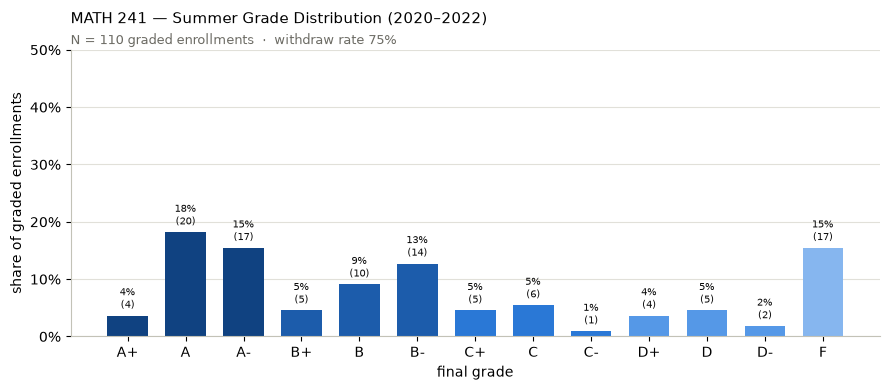

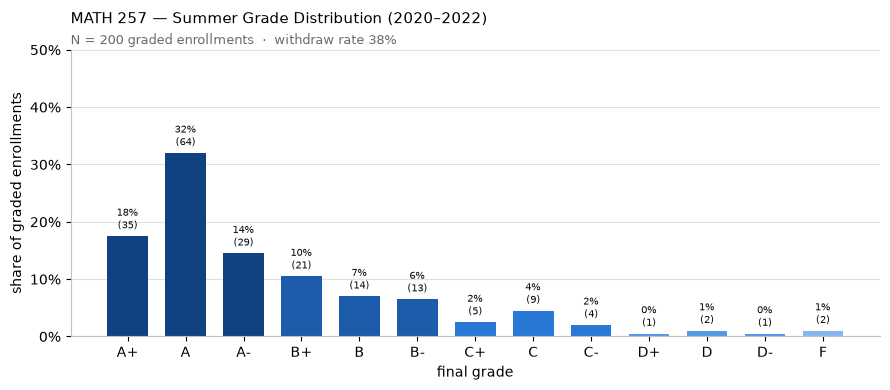

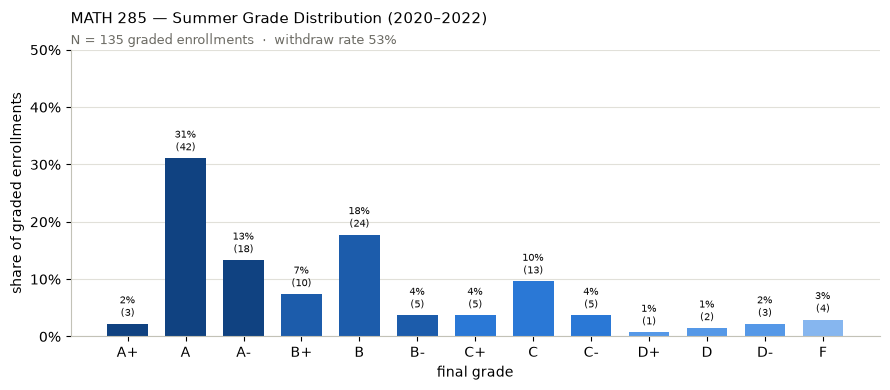

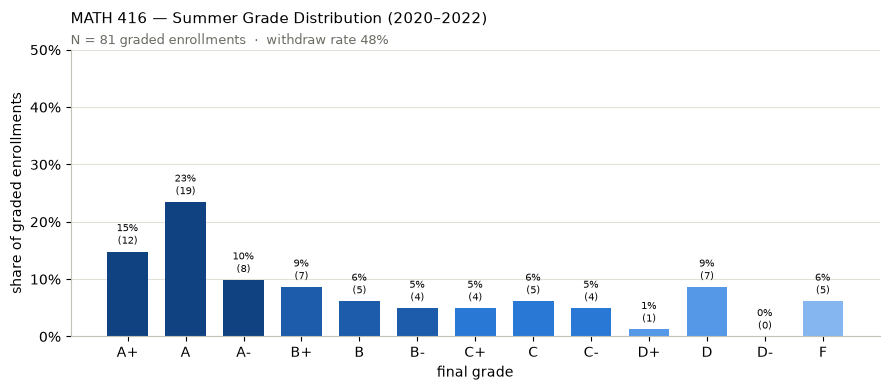

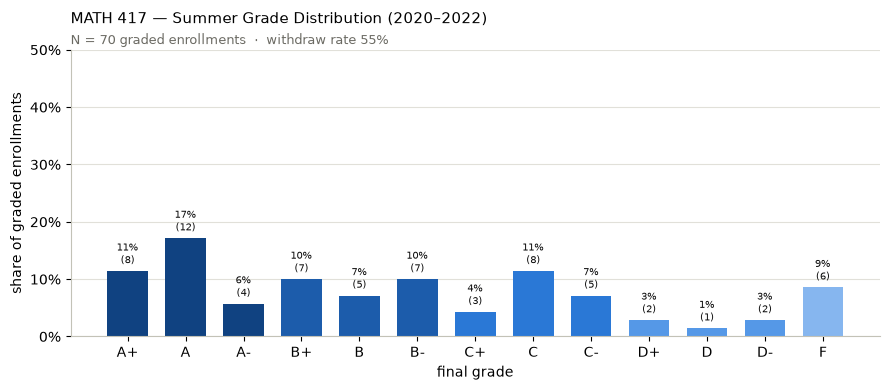

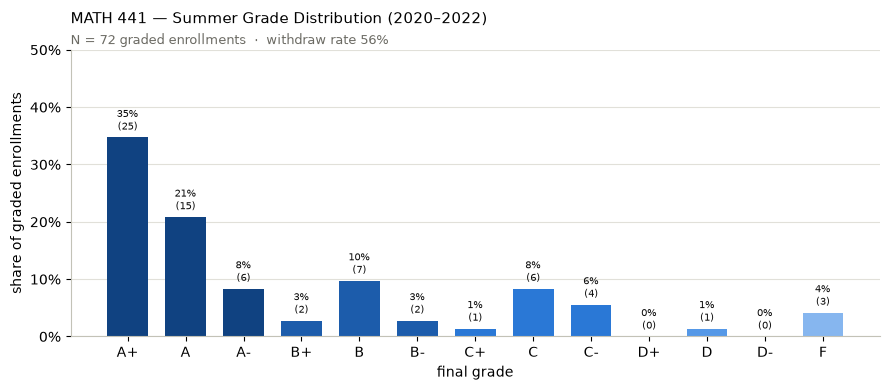

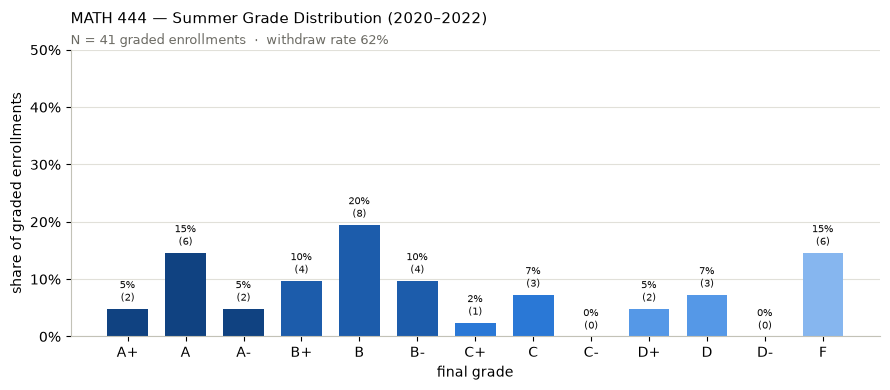

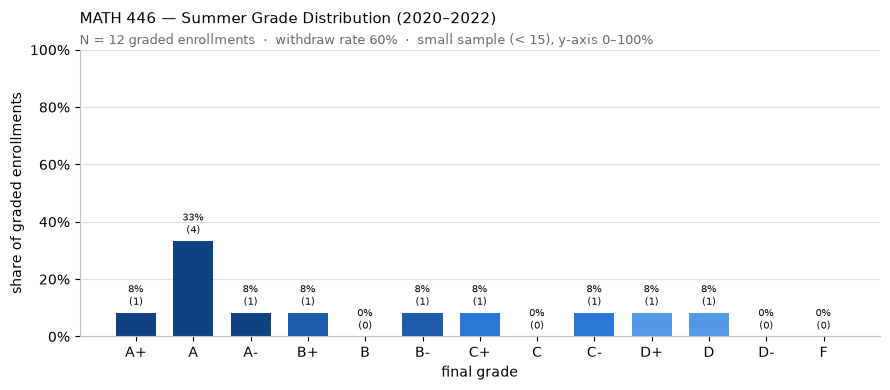

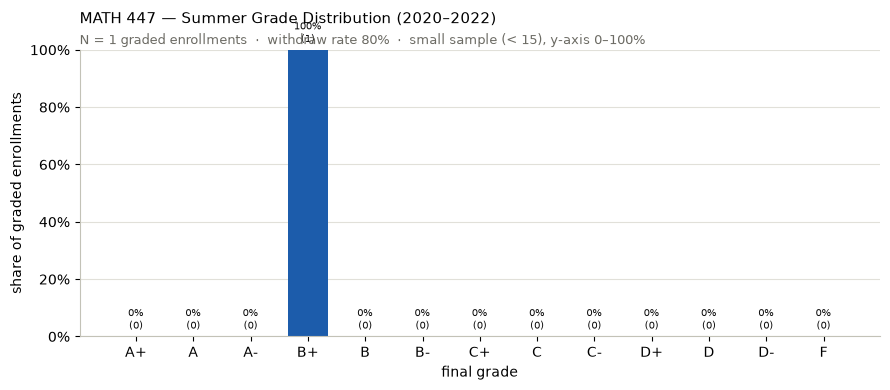

In [65]:
plt.style.use("default")
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"})

INK = "#0b0b0b"
MUTED = "#6b6a63"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
LETTER_COLORS = {"A": "#104281", "B": "#1c5cab", "C": "#2a78d6", "D": "#5598e7", "F": "#86b6ef"}  # one hue, dark = higher
BAR_COLORS = [LETTER_COLORS[g[0]] for g in GRADE_SCALE]

CHART_COURSES = df_grade_counts.index[df_grade_counts["N"] >= MIN_N]
small = df_grade_counts.loc[df_grade_counts["N"] < MIN_N]
print(f"courses charted: {list(CHART_COURSES)}")
print(f"small samples (fewer than {MIN_N} graded enrollments, own 0–100% y-axis):")
display(small)

# same y-axis on every chart: highest single-grade share among charted courses, rounded up to 10
Y_MAX = min(100, int(np.ceil((df_grade_pct.loc[CHART_COURSES].max().max() + 8) / 10) * 10))

def plot_course_distribution(course):
    y_max = Y_MAX if course in CHART_COURSES else 100
    pct = df_grade_pct.loc[course, GRADE_SCALE]
    counts = df_grade_counts.loc[course, GRADE_SCALE]
    n = df_grade_counts.loc[course, "N"]
    wd = course_summary.loc[course, "withdraw_rate"]

    fig, ax = plt.subplots(figsize=(9, 4))
    x = np.arange(len(GRADE_SCALE))
    ax.bar(x, pct, width=0.7, color=BAR_COLORS)
    for xi, p, c in zip(x, pct, counts):
        ax.text(xi, p + y_max * 0.015, f"{p:.0f}%\n({c})", ha="center", va="bottom", fontsize=7.5, color=INK)

    ax.set_xticks(x, GRADE_SCALE)
    ax.set_ylim(0, y_max)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
    ax.set_xlabel("final grade")
    ax.set_ylabel("share of graded enrollments")
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(AXIS)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

    subtitle = f"N = {n} graded enrollments  ·  withdraw rate {wd:.0f}%"
    if n < MIN_N:
        subtitle += f"  ·  small sample (< {MIN_N}), y-axis 0–100%"
    ax.set_title(f"MATH {course} — Summer Grade Distribution (2020–2022)\n", fontsize=11, loc="left")
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9, color=MUTED)

    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f"MATH {course} summer grade distribution.png", dpi=150)
    plt.show()

print(f"shared y-axis: 0–{Y_MAX}%")
for course in df_grade_counts.index:
    plot_course_distribution(course)

### 3.0 All courses on one scale
Every course's grade distribution in one chart, same x (A+ → F) and y (% of graded enrollments) for all. One line per course; each course keeps one color and marker shape everywhere. Lines are used instead of bars because 7 groups × 13 grades of side-by-side bars would be too thin to read; the line only connects a course's points for readability (the grades are discrete). Only courses with at least `MIN_N` graded enrollments are drawn (MATH 446 and 447 are too small to compare; MATH 447's single B+ would show as a 100% spike). Exact numbers: `df_grade_pct` in section 2.


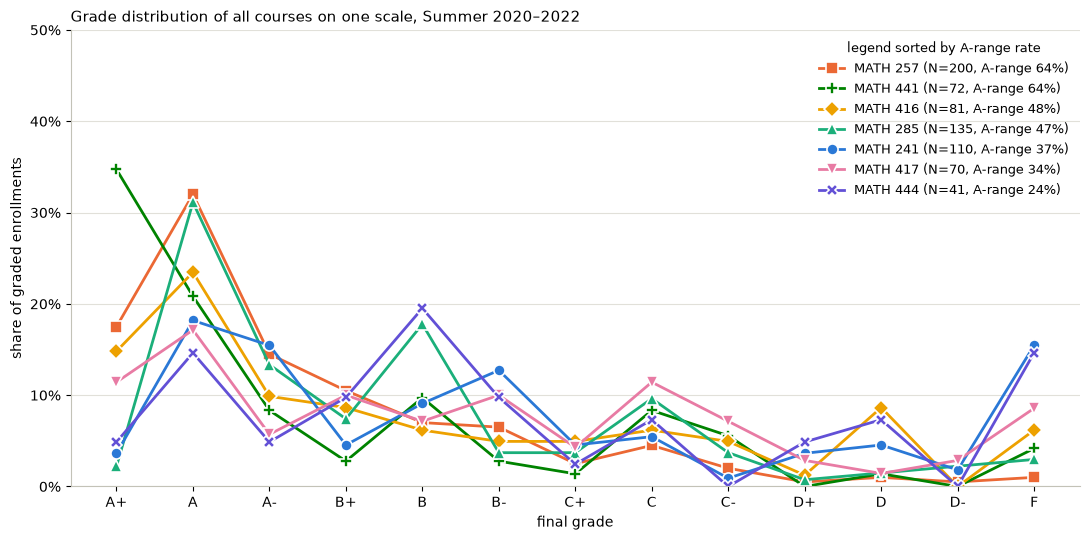

In [66]:
# fixed color + marker per course (by course number, so a course keeps its look in every chart)
COURSE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
COURSE_MARKERS = ["o", "s", "^", "D", "v", "P", "X"]
course_style = {c: (COURSE_COLORS[k], COURSE_MARKERS[k]) for k, c in enumerate(sorted(CHART_COURSES))}

x = np.arange(len(GRADE_SCALE))
fig, ax = plt.subplots(figsize=(11, 5.5))
legend_order = course_summary.loc[CHART_COURSES].sort_values("A_range_rate", ascending=False).index  # legend sorted by A-range rate
for course in legend_order:
    color, marker = course_style[course]
    ax.plot(x, df_grade_pct.loc[course, GRADE_SCALE], color=color, linewidth=2, marker=marker, markersize=8,
            markeredgecolor="white", markeredgewidth=1.2,
            label=f"MATH {course} (N={df_grade_counts.loc[course, 'N']}, A-range {course_summary.loc[course, 'A_range_rate']:.0f}%)")

ax.set_xticks(x, GRADE_SCALE)
ax.set_ylim(0, Y_MAX)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_xlabel("final grade")
ax.set_ylabel("share of graded enrollments")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color(AXIS)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper right", fontsize=9, title="legend sorted by A-range rate", title_fontsize=9)
ax.set_title(f"Grade distribution of all courses on one scale, {YEARS_LABEL}", fontsize=11, loc="left")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "All courses grade distribution.png", dpi=150)
plt.show()


### 3.1 Summary heatmap
All charted courses on one page. Each cell = share of that course's graded enrollments with that grade. Courses are sorted by A-range rate.

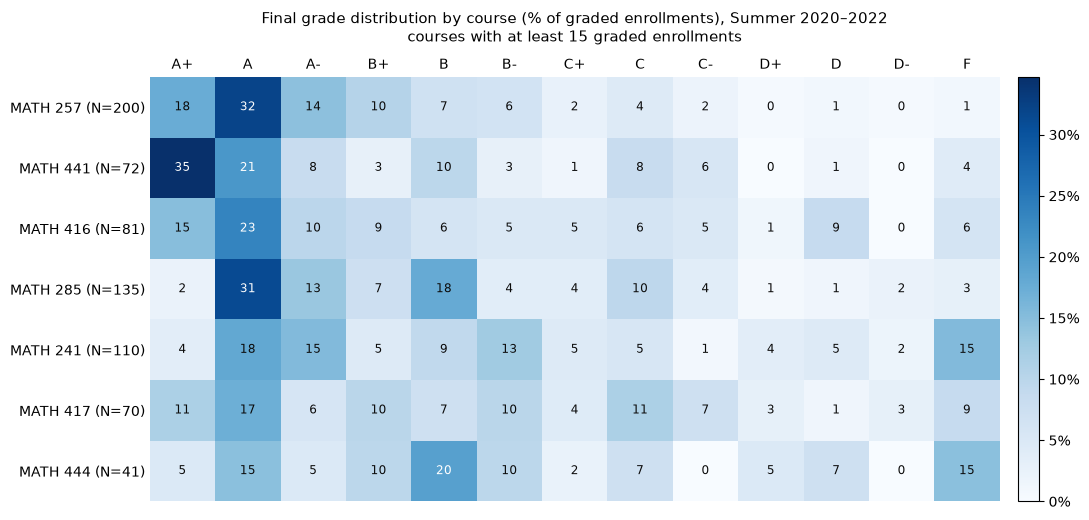

In [67]:
order = course_summary.sort_values("A_range_rate", ascending=False).index
heat = df_grade_pct.loc[[c for c in order if c in CHART_COURSES]]
vmax = heat.to_numpy().max()

fig, ax = plt.subplots(figsize=(11, 0.5 * len(heat) + 1.8))
im = ax.imshow(heat.to_numpy(), cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        value = heat.iat[i, j]
        ax.text(j, i, f"{value:.0f}", ha="center", va="center", fontsize=8.5,
                color="white" if value >= vmax * 0.55 else INK)

ax.set_xticks(range(len(GRADE_SCALE)), GRADE_SCALE)
ax.set_yticks(range(len(heat)), [
    f"MATH {c} (N={df_grade_counts.loc[c, 'N']})"
    for c in heat.index
])
ax.xaxis.tick_top()
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title(f"Final grade distribution by course (% of graded enrollments), {YEARS_LABEL}\n"
             f"courses with at least {MIN_N} graded enrollments", fontsize=11, pad=12)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, format="%d%%")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "Summary heatmap.png", dpi=150)
plt.show()

### 3.2 A-range rate vs D/F rate

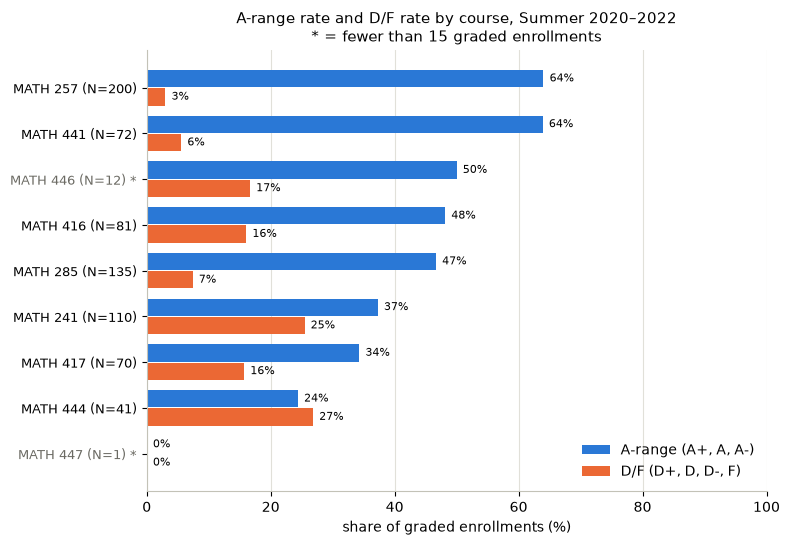

In [68]:
s = course_summary[course_summary["N_graded"] > 0].sort_values("A_range_rate")
y = np.arange(len(s))

fig, ax = plt.subplots(figsize=(8, 0.45 * len(s) + 1.5))
ax.barh(y + 0.2, s["A_range_rate"], height=0.38, color="#2a78d6", label="A-range (A+, A, A-)")
ax.barh(y - 0.2, s["DF_rate"], height=0.38, color="#eb6834", label="D/F (D+, D, D-, F)")
for yi, a, df_ in zip(y, s["A_range_rate"], s["DF_rate"]):
    ax.text(a + 1, yi + 0.2, f"{a:.0f}%", va="center", fontsize=8)
    ax.text(df_ + 1, yi - 0.2, f"{df_:.0f}%", va="center", fontsize=8)
ax.set_yticks(y, [f"MATH {c} (N={n})" + (" *" if n < MIN_N else "") for c, n in zip(s.index, s["N_graded"])], fontsize=9)
for label, n in zip(ax.get_yticklabels(), s["N_graded"]):
    if n < MIN_N:
        label.set_color(MUTED)  # small samples in grey
ax.set_xlim(0, 100)
ax.set_xlabel("share of graded enrollments (%)")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color(AXIS)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")
ax.set_title(f"A-range rate and D/F rate by course, {YEARS_LABEL}\n* = fewer than {MIN_N} graded enrollments", fontsize=11)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "A-range rate vs DF rate.png", dpi=150)
plt.show()

## 4. Comparison & Interpretation
Three angles:

| Dimension | Question | Metric |
|---|---|---|
| Grade concentration | Which courses have the most A-range grades? Which single grade is most common? | A-range rate, most common grade |
| Lower grades | Which courses have more D/F? | D/F rate |
| Grade spread | Even spread vs concentrated in one or two grades? | top-grade share, normalized entropy over the 13 grades (0 = all one grade, 1 = perfectly even) |

In [69]:
p = df_grade_pct[GRADE_SCALE] / 100
entropy = -(p * np.log(p.where(p > 0))).sum(axis=1) / np.log(len(GRADE_SCALE))

interpretation = course_summary.join(pd.DataFrame({
    "most_common_grade": df_grade_pct.idxmax(axis=1),
    "top_grade_share": df_grade_pct.max(axis=1),
    "spread_entropy": entropy,
}))
interpretation.sort_values("A_range_rate", ascending=False).round(2)

,N_graded,A_range_rate,DF_rate,N_known,withdraw_rate,small_sample,most_common_grade,top_grade_share,spread_entropy
course,,,,,,,,,
257,200,64.00,3.00,323,37.77,False,A,32.00,0.78
441,72,63.89,5.56,165,56.36,False,A+,34.72,0.76
446,12,50.00,16.67,30,60.00,True,A,33.33,0.79
416,81,48.15,16.05,157,47.77,False,A,23.46,0.89
285,135,46.67,7.41,285,52.63,False,A,31.11,0.82
241,110,37.27,25.45,442,75.11,False,A,18.18,0.90
417,70,34.29,15.71,156,55.13,False,A,17.14,0.94
444,41,24.39,26.83,109,62.39,False,B,19.51,0.88
447,1,0.00,0.00,5,80.00,True,B+,100.00,-0.00


### Summary report

**Data**
- Summer 2020, 2021, 2022 (AY 2019-20 to 2021-22). Summer 2024–2026 grades are not in nexus (see top of notebook), so this is the fallback window.
- 2,967 summer enrollments → 1,703 after dropping 11 courses NetMath no longer offers (112, 114, 115, 220, 231, 286, 292, 347, 415, 461, 481; 1,264 rows) → 1,672 after removing 31 duplicate student-term-course rows.
- Final grades matched through `students.finalGrade` → `finalgrades`: **723 of 725 Completed enrollments (99.7%)**. 722 have a letter grade (A+ to F), 2 are `Abs`. Withdrawn students have no letter grade (977 rows); only 1 `W` grade exists.
- 7 courses have at least 15 graded enrollments and get a chart: MATH 241, 257, 285, 416, 417, 441, 444. MATH 446 (N = 12) and 447 (N = 1) also get a chart but are flagged as small samples and left out of the heatmap; they appear in the A-range vs D/F chart marked `*`. MATH 314 was not offered in Summer 2020–2022.

**Findings**
1. **Grade concentration.** MATH 257 (64% A-range, N = 200) and MATH 441 (64%, N = 72) have the highest share of A+/A/A-. MATH 441 is the only course where **A+** is the most common grade (35%). MATH 444 has the lowest A-range share (24%), and its most common grade is **B** (20%).
2. **Lower grades.** MATH 444 (27% D/F, of which 15% F) and MATH 241 (25% D/F, 15% F) have the largest share of D/F. MATH 257 (3%), 441 (6%) and 285 (7%) have very few.
3. **Grade spread.** MATH 257 and 441 are concentrated at the top (normalized entropy 0.78 and 0.76). MATH 417 (0.94) and 241 (0.90) are spread across the whole scale. MATH 285 sits in between: it peaks at A (31%) with a second bump at B (18%), and has few D/F.
4. **Year-to-year check (2.1).** MATH 257 had no summer section in 2020, and 2022 makes up 162 of its 200 grades, so its result mostly reflects Summer 2022. MATH 441 rose from ~55% A-range in 2020–21 to 85% in 2022, and MATH 417 fell from ~40% to 19% in 2022. Per-year N is 16–62, so these single-year swings are noisy.
5. **Read with withdraw rate.** Withdraw rates are high (38%–75%). MATH 241 has the highest (75%), so its graded students are only about a quarter of those who enrolled. MATH 257 has the lowest (38%). A course's grade distribution describes the students who finished, not everyone who started.

**Limitations**
- Grade distribution ≠ course difficulty. Student background, why they take the course in summer, grading method and course requirements all affect grades. Wording used: "MATH 257 shows a higher concentration of A-range grades", not "MATH 257 is easier".
- Summer 2020–2021 overlap with the COVID-19 period, and the data is 4–6 years old, so it may not reflect current summer courses.
- Withdrawn students have no letter grade, so a course with a high withdraw rate can look better on A–F alone.
- Course list is from the public NetMath catalog on 2026-11-12; confirm with the supervisor.
- Next step: replace with Summer 2024–2026 once those grades are obtained from outside nexus (registrar / LMS export); sections 2–4 run unchanged on a new grade column.
